# What $I_1$ and $I_2$ Say Before Gerchberg–Saxton

This repo recovers phase by iterating between two intensity traces,
$I_1 = |\,\text{disperse}(E, D_1)|^2$ and $I_2 = |\,\text{disperse}(E, D_2)|^2$.
This notebook asks **what you can get from those traces in closed form, with
no iteration at all**, and turns each answer into a question worth asking
Prof. Jalali.

| Part | Idea | Result |
|---|---|---|
| 1 | sign convention of `disperse()` | a component at frequency $\nu$ arrives at $\tau = -D\nu$ |
| 2 | **numerical group delay by log-differentiation** | $\tau(\nu) = \mathrm{Re}\,\dfrac{\mathcal F[nE]}{\mathcal F[E]}$, exact, no unwrapping |
| 3 | **the $\langle t\rangle$, $\langle t^2\rangle$ moment identity** | $\sigma^2(D)$ is *exactly* quadratic in $D$ for any pulse shape |
| 4 | chirp from $I_1, I_2$ + spectrum | two equations, two unknowns, closed form |
| 5 | noise | error $\propto 1/|D_1 - D_2|$, the diversity requirement seen another way |
| 6 | physical group velocity in silica | SymPy-exact vs. finite-difference derivatives |
| 7 | **questions for Jalali**, with numbers | — |

Module: [`dgs/pulse_moments_group_delay.py`](../dgs/pulse_moments_group_delay.py).
Units are the repo's: $t$ = sample index $n$, $\nu$ = `np.fft.fftfreq` in cycles/sample.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.gs_core import disperse
from dgs.pulse_moments_group_delay import (
    chirped_pulse, group_delay_fft, group_delay_logdiff_fd, group_delay_unwrap, wrapped_error,
    temporal_moments, spectral_moments, predicted_sigma2, chirp_from_two_traces,
    quadratic_from_three_traces, chirp_estimate_spread,
    silica_index, group_index_exact, group_index_fd, material_dispersion_ps_nm_km, group_velocity,
)
N = 8192; NU = np.fft.fftfreq(N)

# 1. Sign convention: which way does `disperse()` push each frequency?

`disperse(E, D)` multiplies the spectrum by $H(\nu) = e^{i\pi D\nu^2}$. Its spectral
phase is $\psi = \pi D\nu^2$. With NumPy's FFT convention, the group delay is
$\tau = -\frac{1}{2\pi}\frac{d\psi}{d\nu} = -D\nu$. Check it with a narrowband
pulse on a carrier $\nu_0$:

In [2]:
E = chirped_pulse(T0=20, nu0=0.05)
for D in (1000, -1000, 3000):
    m, _ = temporal_moments(np.abs(disperse(E, D))**2)
    print(f"D = {D:6d}:  measured shift {m - N/2:8.3f} samples,  predicted -D·ν0 = {-D*0.05:8.3f}")

D =   1000:  measured shift  -50.000 samples,  predicted -D·ν0 =  -50.000
D =  -1000:  measured shift   50.000 samples,  predicted -D·ν0 =   50.000
D =   3000:  measured shift -150.000 samples,  predicted -D·ν0 = -150.000


# 2. Numerical group delay by logarithmic differentiation

Write the spectrum as $\tilde E(\nu) = a(\nu)\,e^{i\psi(\nu)}$. Take the log and
differentiate:

$$\frac{d}{d\nu}\ln\tilde E = \frac{a'}{a} + i\,\psi' \quad\Longrightarrow\quad
\tau(\nu) = -\frac{1}{2\pi}\,\mathrm{Im}\frac{\tilde E'}{\tilde E}$$

The imaginary part *is* the group delay, and the phase never has to be
unwrapped. Better still, $\tilde E'$ is known **exactly**. Differentiating the
DFT sum term by term gives $\tilde E'(\nu) = \mathcal F[-2\pi i\,n\,E[n]]$, so

$$\boxed{\tau(\nu) = \mathrm{Re}\,\frac{\mathcal F[\,n\,E\,]}{\mathcal F[\,E\,]}}$$

That's two FFTs and a division, with no derivative step. Compare it with the two
usual routes on a pulse dispersed by increasing $D$:

- **unwrap + gradient:** unwrap $\psi$, then take a central difference
- **log-derivative, finite difference:** `np.gradient` applied to the complex $\tilde E$, then $\mathrm{Im}(\tilde E'/\tilde E)$

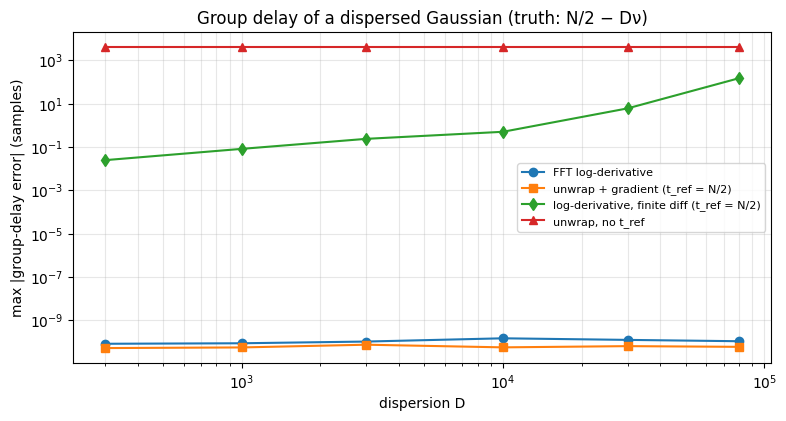

FFT log-derivative                          8.19e-11   8.64e-11   1.04e-10   1.46e-10   1.24e-10   1.07e-10
unwrap + gradient (t_ref = N/2)             5.18e-11   5.55e-11   7.41e-11   5.59e-11   6.37e-11   5.91e-11
log-derivative, finite diff (t_ref = N/2)   2.46e-02   8.16e-02   2.37e-01   5.02e-01   6.06e+00   1.49e+02
unwrap, no t_ref                            4.10e+03   4.10e+03   4.10e+03   4.10e+03   4.10e+03   4.10e+03


In [3]:
G = chirped_pulse(T0=40)
Ds = np.array([300, 1000, 3000, 10000, 30000, 80000])
errs = {k: [] for k in ("FFT log-derivative", "unwrap + gradient (t_ref = N/2)",
                        "log-derivative, finite diff (t_ref = N/2)", "unwrap, no t_ref")}
for D in Ds:
    Ed = disperse(G, D); Ak = np.abs(np.fft.fft(Ed)); w = Ak > 1e-3*Ak.max()
    truth = N/2 - D*NU[w]
    for k, tau in zip(errs, (group_delay_fft(Ed), group_delay_unwrap(Ed, t_ref=N/2),
                             group_delay_logdiff_fd(Ed, t_ref=N/2), group_delay_unwrap(Ed))):
        errs[k].append(np.max(np.abs(wrapped_error(tau[w], truth, N))) + 1e-16)

fig, ax = plt.subplots(figsize=(9, 4.3))
for (k, e), mk in zip(errs.items(), "osd^"):
    ax.loglog(Ds, e, mk + "-", label=k)
ax.set(xlabel="dispersion D", ylabel="max |group-delay error| (samples)",
       title="Group delay of a dispersed Gaussian (truth: N/2 − Dν)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both"); plt.show()
for k, e in errs.items():
    print(f"{k:42s}", "  ".join(f"{x:9.2e}" for x in e))

**What the plot shows.**

1. **The FFT log-derivative is exact (about $10^{-10}$) at every $D$.** It's the
   estimator to use on simulated or reconstructed fields.
2. **Unwrap + gradient is also exact here, but only for a lucky reason.**
   Pure GVD has a *quadratic* phase, and a central difference is exact on a
   quadratic. Add $\beta_3$ (cubic phase) and that luck runs out.
3. **The finite-difference log-derivative degrades as $D$ grows.** A
   neighbor-bin difference of $e^{i\psi}$ measures $\sin\Delta\psi$, not
   $\Delta\psi$. Log-differentiation is only exact when the derivative itself is.
4. **"Unwrap, no t_ref" fails completely.** A pulse sitting at the window center
   $N/2$ gives a linear spectral phase of exactly $\pi$ per bin, the Nyquist limit
   of any neighbor-bin phase estimate. You have to remove the bulk delay first.
   This trap is easy to fall into with real oscilloscope data.

# 3. The moment identity: $\sigma^2(D)$ is exactly a parabola

Let $w(\nu) = |\tilde E|^2/\sum|\tilde E|^2$ be the normalized spectrum. Parseval
applied to $\mathcal F[nE] \propto \tilde E'$ turns time moments into spectral
averages:

$$\langle t\rangle = \langle\tau\rangle_w,\qquad
\langle t^2\rangle = \Big\langle \tau^2 + \big(\tfrac{a'}{2\pi a}\big)^2\Big\rangle_w$$

Dispersion only changes the phase, $\tau \to \tau_0 - D\nu$, and leaves $a(\nu)$
alone. Expanding:

$$\boxed{\;\langle t\rangle(D) = \langle\tau_0\rangle - D\langle\nu\rangle,\qquad
\sigma^2(D) = \sigma_0^2 \;-\; 2D\,\mathrm{cov}(\nu,\tau_0) \;+\; D^2\,\mathrm{var}(\nu)\;}$$

This holds for **any pulse shape**, as long as the field is band-limited and the
dispersion is purely second order. The covariance term $\mathrm{cov}(\nu,\tau_0)$
is the chirp: it measures whether high frequencies lead or lag low ones. Check it
on a sech pulse with cubic phase, which is far from Gaussian:

gauss chirp=0 cubic=0:  max relative error 3.5e-16
gauss chirp=3 cubic=0:  max relative error 3.3e-14
sech  chirp=3 cubic=1:  max relative error 4.5e-09


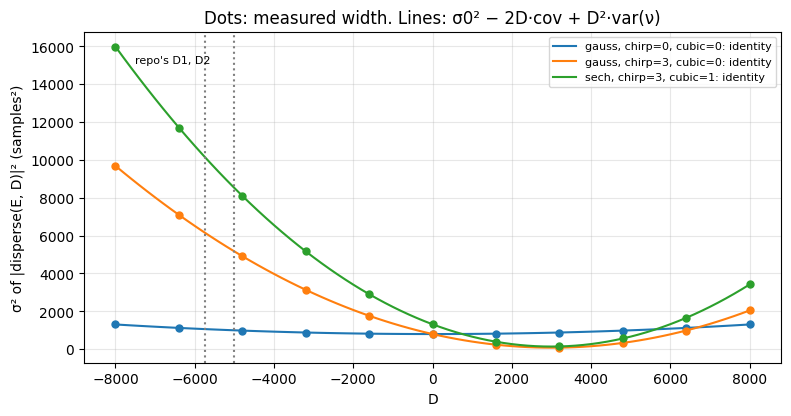

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.3))
Dgrid = np.linspace(-8000, 8000, 81)
for (shape, ch, cu), col in ((("gauss", 0, 0), "C0"), (("gauss", 3, 0), "C1"), (("sech", 3, 1), "C2")):
    E = chirped_pulse(chirp=ch, cubic=cu, shape=shape)
    sm = spectral_moments(E); _, s0 = temporal_moments(np.abs(E)**2)
    meas = [temporal_moments(np.abs(disperse(E, D))**2)[1] for D in Dgrid[::8]]
    ax.plot(Dgrid, predicted_sigma2(Dgrid, s0, sm["cov_nu_tau"], sm["var_nu"]), col,
            label=f"{shape}, chirp={ch}, cubic={cu}: identity")
    ax.plot(Dgrid[::8], meas, "o", color=col, ms=5)
    rel = max(abs(m - predicted_sigma2(D, s0, sm["cov_nu_tau"], sm["var_nu"]))/m for m, D in zip(meas, Dgrid[::8]))
    print(f"{shape:5s} chirp={ch} cubic={cu}:  max relative error {rel:.1e}")
ax.axvline(-5000, color="0.5", ls=":"); ax.axvline(-5750, color="0.5", ls=":")
ax.text(-5600, ax.get_ylim()[1]*0.9, "repo's D1, D2", fontsize=8, ha="right")
ax.set(xlabel="D", ylabel="σ² of |disperse(E, D)|² (samples²)",
       title="Dots: measured width. Lines: σ0² − 2D·cov + D²·var(ν)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

# 4. The chirp from $I_1$, $I_2$, and a spectrum, in closed form

The parabola has three coefficients. $\mathrm{var}(\nu)$ comes from an **optical
spectrum analyzer** trace, which is a cheap, slow measurement. Subtract
$D_i^2\,\mathrm{var}(\nu)$ from each measured width and two *linear* equations
are left:

$$y_i \equiv \sigma^2(D_i) - D_i^2\,\mathrm{var}(\nu) = \sigma_0^2 - 2D_i\,\mathrm{cov}
\quad\Rightarrow\quad \mathrm{cov} = -\frac{y_1-y_2}{2(D_1-D_2)}$$

Without a spectrum you need a **third** intensity trace to fit the parabola.

For a chirped Gaussian, $E \propto \exp[-(1-iC)\,s^2/2]$ with $s = (n - N/2)/T_0$,
the group delay is linear, $\tau_0 = b\,\nu$, with
$b = \dfrac{2\pi T_0^2\,C}{1+C^2}$. So $b = \mathrm{cov}/\mathrm{var}(\nu)$, and the
parabola's minimum at $D = b$ is the **dispersion that compresses the pulse**.

from I1, I2 + spectrum:  σ0² = 800.0000   (direct: 800.0000)
chirp slope b = cov/var = 3015.9289   (analytic 2πT0²C/(1+C²) = 3015.9289)
→ the pulse compresses to its minimum width at D = 3015.9

three traces, no spectrum: var(ν) = 7.915717e-05  (true 7.915717e-05),  cov = 0.2387  (true 0.2387)


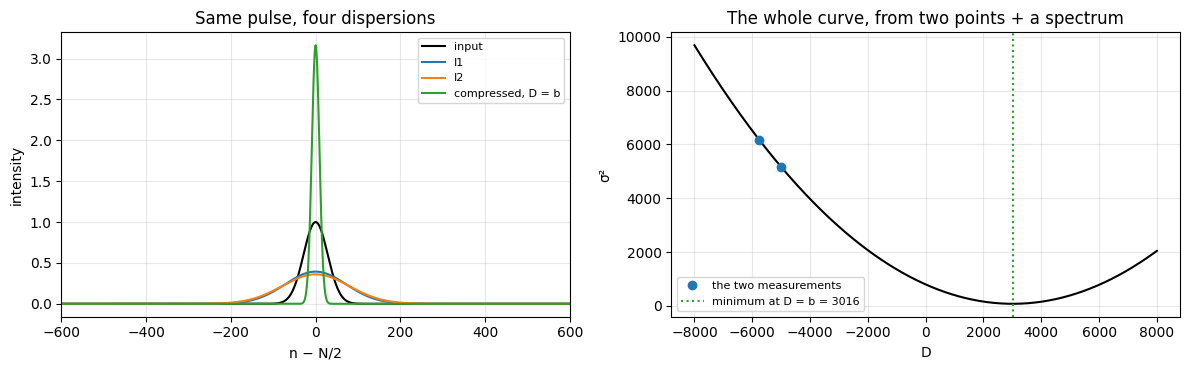

In [5]:
C, T0 = 3.0, 40.0
E = chirped_pulse(T0=T0, chirp=C)
sm = spectral_moments(E)
I1, I2 = (np.abs(disperse(E, D))**2 for D in (-5000, -5750))
s0_est, cov_est = chirp_from_two_traces(I1, I2, -5000, -5750, sm["var_nu"])
b_est, b_true = cov_est / sm["var_nu"], 2*np.pi*T0**2*C/(1 + C**2)
print(f"from I1, I2 + spectrum:  σ0² = {s0_est:.4f}   (direct: {temporal_moments(np.abs(E)**2)[1]:.4f})")
print(f"chirp slope b = cov/var = {b_est:.4f}   (analytic 2πT0²C/(1+C²) = {b_true:.4f})")
print(f"→ the pulse compresses to its minimum width at D = {b_est:.1f}")

Ds3 = [-5000, -5750, -3000]
s0_3, cov_3, var_3 = quadratic_from_three_traces([np.abs(disperse(E, D))**2 for D in Ds3], Ds3)
print(f"\nthree traces, no spectrum: var(ν) = {var_3:.6e}  (true {sm['var_nu']:.6e}),  cov = {cov_3:.4f}  (true {sm['cov_nu_tau']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
nn = np.arange(N)
for D, col, lab in ((0, "k", "input"), (-5000, "C0", "I1"), (-5750, "C1", "I2"), (b_est, "C2", "compressed, D = b")):
    axes[0].plot(nn - N/2, np.abs(disperse(E, D))**2, col, label=lab)
axes[0].set(xlim=(-600, 600), xlabel="n − N/2", ylabel="intensity", title="Same pulse, four dispersions")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
Dg = np.linspace(-8000, 8000, 400)
axes[1].plot(Dg, predicted_sigma2(Dg, s0_est, cov_est, sm["var_nu"]), "k")
axes[1].plot([-5000, -5750], [temporal_moments(I)[1] for I in (I1, I2)], "o", color="C0", label="the two measurements")
axes[1].axvline(b_est, color="C2", ls=":", label=f"minimum at D = b = {b_est:.0f}")
axes[1].set(xlabel="D", ylabel="σ²", title="The whole curve, from two points + a spectrum")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 5. Noise: why measurement diversity matters, seen from the moments

The chirp estimate divides by $D_1 - D_2$, so measurement noise is amplified by
$1/|D_1-D_2|$. That's the same requirement as the repo's GS convergence finding
(the two traces need to differ enough), now in a form you can calculate.

There's a second, nastier problem. $\sigma^2$ weights every sample by
$(n-\langle n\rangle)^2$, so **noise far from the pulse dominates**. You can zero
everything below a noise floor, but that clips the pulse's wings, which carry
the chirp. The result is less variance and more bias:

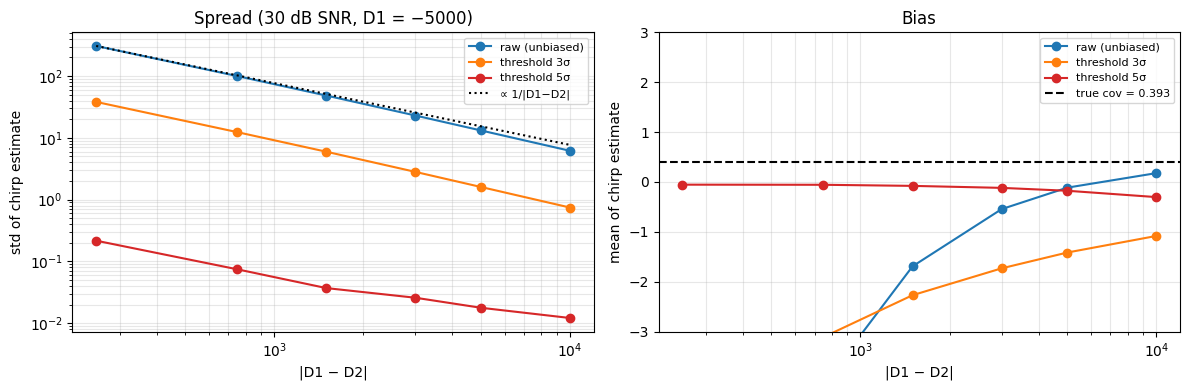

|D1−D2| : [  250   750  1500  3000  5000 10000]
raw    std : [306.606  99.676  48.259  22.939  13.135   6.153]
th=3   std : [38.087 12.346  5.951  2.807  1.598  0.743]
th=5   std : [0.216 0.074 0.037 0.026 0.018 0.012]


In [6]:
E = chirped_pulse(chirp=3.0, cubic=1.0, shape="sech")
true = spectral_moments(E)["cov_nu_tau"]
D2s = [-5250, -5750, -6500, -8000, -10000, -15000]
rows = []
for th in (None, 3, 5):
    s_, m_ = zip(*[chirp_estimate_spread(E, -5000, D2, snr_db=30, n_trials=150, threshold=th)[:2] for D2 in D2s])
    rows.append((th, np.array(s_), np.array(m_)))

dD = np.abs(np.array(D2s) + 5000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (th, s_, m_), col in zip(rows, ("C0", "C1", "C3")):
    lab = "raw (unbiased)" if th is None else f"threshold {th}σ"
    axes[0].loglog(dD, s_, "o-", color=col, label=lab)
    axes[1].semilogx(dD, m_, "o-", color=col, label=lab)
axes[0].loglog(dD, rows[0][1][0]*dD[0]/dD, "k:", label="∝ 1/|D1−D2|")
axes[0].set(xlabel="|D1 − D2|", ylabel="std of chirp estimate", title="Spread (30 dB SNR, D1 = −5000)")
axes[1].axhline(true, color="k", ls="--", label=f"true cov = {true:.3f}")
axes[1].set(xlabel="|D1 − D2|", ylabel="mean of chirp estimate", title="Bias", ylim=(-3, 3))
for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
print("|D1−D2| :", dD)
for th, s_, m_ in rows:
    print(f"{'raw' if th is None else f'th={th}':6s} std :", np.array2string(s_, precision=3))

**How to read this.** For the repo's default $|D_1-D_2| = 750$, the raw
moment estimate of the chirp is useless at 30 dB SNR: its spread is hundreds of
times the true value. Increasing the separation helps as $1/|D_1-D_2|$, but in a
wide window that isn't enough. Thresholding makes the estimate precise but
wrong.

So moments make a good **analytic check** and possibly a **starting guess**, but
they aren't a replacement for GS on noisy data. In practice you'd use a window
around the pulse with baseline subtraction, which is what question 3 in Part 7
asks about.

# 6. Physical group velocity in fused silica

In real units, the group index and dispersion come from the refractive index
$n(\lambda)$ (Malitson Sellmeier for fused silica):

$$n_g = n - \lambda\frac{dn}{d\lambda},\qquad v_g = \frac{c}{n_g},\qquad
D_\lambda = -\frac{\lambda}{c}\frac{d^2n}{d\lambda^2}$$

SymPy differentiates the Sellmeier formula exactly, and that serves as the
reference for checking the numerical derivatives.

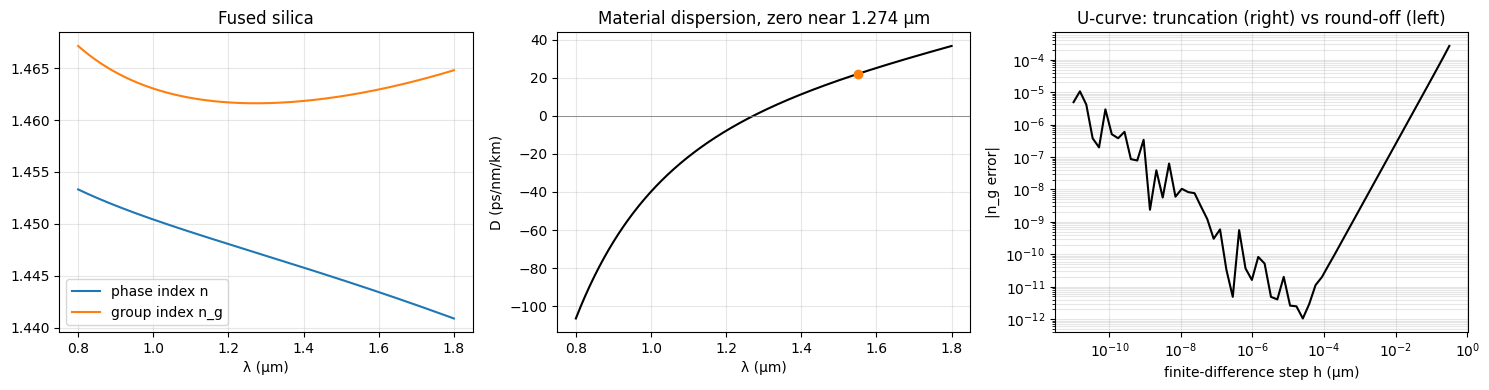

at 1550 nm: n = 1.44402, n_g = 1.46260, v_g = 2.0497e8 m/s
material D = 21.91 ps/nm/km  (SMF-28 is ~17: its waveguide term subtracts ~5)
group delay through 10 km: 48.786 µs; spread across a 10 nm band: 2.19 ns


In [7]:
lam = np.linspace(0.8, 1.8, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(lam, silica_index(lam), label="phase index n"); axes[0].plot(lam, group_index_exact(lam), label="group index n_g")
axes[0].set(xlabel="λ (µm)", title="Fused silica"); axes[0].legend(); axes[0].grid(alpha=0.3)
Dm = material_dispersion_ps_nm_km(lam)
axes[1].plot(lam, Dm, "k"); axes[1].axhline(0, color="0.5", lw=0.6)
zdw = lam[np.argmin(np.abs(Dm))]
axes[1].plot(1.55, material_dispersion_ps_nm_km(1.55), "o", color="C1")
axes[1].set(xlabel="λ (µm)", ylabel="D (ps/nm/km)", title=f"Material dispersion, zero near {zdw:.3f} µm")
axes[1].grid(alpha=0.3)
hs = np.logspace(-11, -0.5, 60)
axes[2].loglog(hs, [abs(float(group_index_fd(1.55, h) - group_index_exact(1.55))) + 1e-18 for h in hs], "k")
axes[2].set(xlabel="finite-difference step h (µm)", ylabel="|n_g error|",
            title="U-curve: truncation (right) vs round-off (left)"); axes[2].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

L_km = 10
ng = float(group_index_exact(1.55))
print(f"at 1550 nm: n = {float(silica_index(1.55)):.5f}, n_g = {ng:.5f}, v_g = {float(group_velocity(1.55))/1e8:.4f}e8 m/s")
print(f"material D = {float(material_dispersion_ps_nm_km(1.55)):.2f} ps/nm/km  (SMF-28 is ~17: its waveguide term subtracts ~5)")
print(f"group delay through {L_km} km: {L_km*1e3*ng/2.998e8*1e6:.3f} µs; "
      f"spread across a 10 nm band: {float(material_dispersion_ps_nm_km(1.55))*10*L_km/1e3:.2f} ns")

The U-curve explains why careful numerical derivatives are subtle. A large
step $h$ gives *truncation* error $\propto h^2$. A tiny step gives *round-off*
error $\propto \epsilon_\text{mach}/h$. The best step is around $10^{-5}$ µm. The
FFT log-derivative in Part 2 sidesteps the whole trade-off because it never
takes a difference.

# 7. Questions for Prof. Jalali, now backed by numbers

Each question points to a result in this notebook that you can show him.

**On the $I_1$/$I_2$ measurement**

1. *"I find $\sigma^2(D)$ is exactly quadratic in $D$ for any pulse shape (Part 3),
   so two traces plus an OSA spectrum give the chirp in closed form (Part 4).
   Is that used anywhere in time-stretch systems as a calibration, or as a
   starting guess for iterative retrieval?"*
2. *"The noise in the moment-based chirp scales as $1/|D_1-D_2|$ (Part 5). My GS
   simulations also need large diversity. How do you choose $D_1$ and $D_2$ on a
   real bench: two fiber spools, or one fiber read out at two points?"*
3. *"Second moments are dominated by baseline noise far from the pulse
   (Part 5). How do you handle baseline subtraction and windowing on real
   oscilloscope traces?"*

**On numerical group velocity**

4. *"Computing the group delay as $\mathrm{Re}\,\mathcal F[nE]/\mathcal F[E]$ avoids
   phase unwrapping (Part 2). Do you calibrate $D$ by measuring group delay
   against wavelength, and do you fit a polynomial or differentiate the measured
   phase?"*
5. *"At what bandwidth does $\beta_3$ (cubic phase) start to break the
   quadratic-phase model $H = e^{i\pi D\nu^2}$ in your systems?"*

**On real data**

6. *"Could I get a real $I_1$/$I_2$ dataset, maybe from Yiming, to test both the
   moment estimate and GS on?"*

## Exercises

1. Use the Part 4 compression estimate $D = b$ to seed `retrieve_phase` with a
   chirped initial guess instead of zero phase. Does GS converge in fewer
   iterations?
2. Add a cubic spectral phase to $H$ (i.e. $\beta_3$) and rerun Part 2. Which
   estimator breaks first?
3. Derive $\langle t^2\rangle = \langle\tau^2 + (a'/2\pi a)^2\rangle_w$ yourself from
   Parseval. Where does the amplitude term come from?
4. Repeat Part 5 with a Hann window of width $\pm4\sigma$ around $\langle t\rangle$
   instead of a threshold. Is it biased?
5. These are the same moments as $\langle x\rangle$, $\langle x^2\rangle$ in quantum
   mechanics, with $D$ playing the role of time and the "free particle" being the
   dispersed pulse. Connect $\sigma^2(D)$ to free-particle wave-packet spreading
   (see `ehrenfest_theorem.ipynb`).